# Projet 5 – Détection de fraude bancaire
## Phase 2 · Diagnostic des données (tâches 2.1 à 2.6)

**Équipe :** Yacine Hammadache · Kousseila Tekerrabet
**Cours :** Collecte et nettoyage des données (La Cité) – méthodes des semaines 07 et 08
**Date :** 30 octobre 2026

| Tâche | Ticket Jira | Résultat attendu |
|---|---|---|
| 2.1 Charger les fichiers et les codes MCC, inventorier les variables | KAN-10 | Dictionnaire de données |
| 2.2 Documenter les relations clients – cartes – transactions | KAN-11 | Schéma relationnel |
| 2.3 Convertir les formats (montants « $ », dates, codes postaux) | KAN-12 | Rapport des types |
| 2.4 Mesurer les valeurs manquantes | KAN-13 | Tableau des manquants |
| 2.5 Repérer les doublons et les identifiants sans correspondance | KAN-14 | Rapport d'intégrité |
| 2.6 Détecter les valeurs aberrantes et les incohérences | KAN-15 | Rapport des aberrations |

**Principes suivis (semaine 07)**
- Les fichiers bruts ne sont jamais modifiés. Les versions converties sont enregistrées à part (`data/interim/`).
- Chaque étape est dans ce notebook, donc reproductible.
- Chaque constat est consigné dans un **journal** (combien de valeurs, quelle règle, quelle piste).
- Ce notebook **diagnostique** : il mesure et signale. Les corrections sont faites dans la tâche 2.7, car *détecter n'est pas supprimer*.

In [1]:
import json, re, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Dossier obtenu en décompressant donnees_banque.zip
DATA_DIR = Path("data/donnees banque")
INTERIM_DIR = Path("data/interim")      # données converties (tâche 2.3)
OUT_DIR = Path("sorties")               # tableaux de résultats
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Journal des constats : une ligne par décision ou constat
JOURNAL = []
def journal(tache, table, variable, constat, n, piste):
    JOURNAL.append({"tache": tache, "table": table, "variable": variable,
                    "constat": constat, "n": n, "piste_pour_2_7": piste})

def nb(x):                      # 13305915 -> "13 305 915"
    return f"{int(x):,}".replace(",", " ")

def pct(x, n):
    return f"{100 * x / n:.2f} %"
print("pandas", pd.__version__)

pandas 3.0.5


---
# Tâche 2.1 – Chargement et inventaire des variables (KAN-10)

Le projet comprend cinq fichiers :

| Fichier | Contenu |
|---|---|
| `users_data.csv` | clients |
| `cards_data.csv` | cartes |
| `transactions_data.csv` | transactions (≈ 1,26 Go) |
| `mcc_codes.json` | libellés des catégories de commerçants |
| `fraud_labels.json` | étiquette de fraude par transaction |

Le gros fichier de transactions est lu avec le moteur `pyarrow`, environ 10 fois plus rapide que le moteur par défaut. Les dates sont d'abord lues comme du texte : leur conversion fait partie de la tâche 2.3.

In [2]:
t0 = time.time()
users_raw = pd.read_csv(DATA_DIR / "users_data.csv")
cards_raw = pd.read_csv(DATA_DIR / "cards_data.csv")
try:
    tx_raw = pd.read_csv(DATA_DIR / "transactions_data.csv", engine="pyarrow", dtype={"date": "string"})
except (ImportError, ValueError):          # si pyarrow n'est pas installé
    tx_raw = pd.read_csv(DATA_DIR / "transactions_data.csv", dtype={"date": "string"}, low_memory=False)

with open(DATA_DIR / "mcc_codes.json", encoding="utf-8") as f:
    mcc_dict = json.load(f)
with open(DATA_DIR / "fraud_labels.json", encoding="utf-8") as f:
    labels_json = json.load(f)
print("Clé(s) du fichier JSON des étiquettes :", list(labels_json.keys()))

mcc_raw = pd.DataFrame(list(mcc_dict.items()), columns=["mcc", "categorie"])
labels_raw = pd.DataFrame(list(labels_json["target"].items()), columns=["transaction_id", "fraud"])
del labels_json, mcc_dict
print(f"Chargement terminé en {time.time() - t0:.0f} s")

TABLES_RAW = {"users": users_raw, "cards": cards_raw, "transactions": tx_raw,
              "mcc_codes": mcc_raw, "fraud_labels": labels_raw}
inventaire = pd.DataFrame([{"table": k, "lignes": len(v), "colonnes": v.shape[1],
                            "memoire_Mo": round(v.memory_usage(deep=True).sum() / 1e6, 1)}
                           for k, v in TABLES_RAW.items()])
inventaire

Clé(s) du fichier JSON des étiquettes : ['target']


Chargement terminé en 29 s


,table,lignes,colonnes,memoire_Mo
0,users,2000,14,0.3
1,cards,6146,13,0.9
2,transactions,13305915,12,1977.3
3,mcc_codes,109,2,0.0
4,fraud_labels,8914963,2,230.4


In [3]:
for nom in ["users", "cards", "transactions"]:
    display(Markdown(f"**{nom}** – 3 premières lignes"))
    display(TABLES_RAW[nom].head(3))

**users** – 3 premières lignes

,id,current_age,retirement_age,birth_year,birth_month,gender,address,latitude,longitude,per_capita_income,yearly_income,total_debt,credit_score,num_credit_cards
0,825,53,66,1966,11,Female,462 Rose Lane,34.15,-117.76,$29278,$59696,$127613,787,5
1,1746,53,68,1966,12,Female,3606 Federal Boulevard,40.76,-73.74,$37891,$77254,$191349,701,5
2,1718,81,67,1938,11,Female,766 Third Drive,34.02,-117.89,$22681,$33483,$196,698,5


**cards** – 3 premières lignes

,id,client_id,card_brand,card_type,card_number,expires,cvv,has_chip,num_cards_issued,credit_limit,acct_open_date,year_pin_last_changed,card_on_dark_web
0,4524,825,Visa,Debit,4344676511950444,12/2022,623,YES,2,$24295,09/2002,2008,No
1,2731,825,Visa,Debit,4956965974959986,12/2020,393,YES,2,$21968,04/2014,2014,No
2,3701,825,Visa,Debit,4582313478255491,02/2024,719,YES,2,$46414,07/2003,2004,No


**transactions** – 3 premières lignes

,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors
0,7475327,2010-01-01 00:01:00,1556,2972,$-77.00,Swipe Transaction,59935,Beulah,ND,58523.0,5499,NaN
1,7475328,2010-01-01 00:02:00,561,4575,$14.57,Swipe Transaction,67570,Bettendorf,IA,52722.0,5311,NaN
2,7475329,2010-01-01 00:02:00,1129,102,$80.00,Swipe Transaction,27092,Vista,CA,92084.0,4829,NaN


### Nettoyage des noms de colonnes (semaine 07)

On applique la fonction de normalisation $f = f_5 \circ f_4 \circ f_3 \circ f_2 \circ f_1$ :

| Étape | Transformation |
|---|---|
| $f_1$ | retirer les espaces aux extrémités |
| $f_2$ | mettre en minuscules |
| $f_3$ | retirer les accents |
| $f_4$ | remplacer les caractères non alphanumériques par `_` |
| $f_5$ | fusionner les `_` et retirer ceux en trop |

On vérifie deux propriétés :
- **injectivité** : il n'y a pas de collision entre deux noms ;
- **idempotence** : $f(f(\nu)) = f(\nu)$.

Les identifiants `id` sont ensuite renommés de façon explicite (`client_id`, `card_id`, `transaction_id`). Cela les rend identiques d'une table à l'autre et prépare les jointures.

In [4]:
def normaliser_nom(nom: str) -> str:
    nom = nom.strip().lower()                                                     # f1, f2
    nom = unicodedata.normalize("NFKD", nom).encode("ascii", "ignore").decode()   # f3
    nom = re.sub(r"[^a-z0-9]", "_", nom)                                          # f4
    return re.sub(r"_+", "_", nom).strip("_")                                     # f5

for nom, df in TABLES_RAW.items():
    nouveaux = [normaliser_nom(c) for c in df.columns]
    assert len(set(nouveaux)) == len(nouveaux), f"Collision de noms dans {nom}"     # injectivité
    assert all(normaliser_nom(c) == c for c in nouveaux), "f non idempotente"       # idempotence
    modifies = [(a, b) for a, b in zip(df.columns, nouveaux) if a != b]
    df.columns = nouveaux
    print(f"{nom:13s}: noms déjà conformes" if not modifies else f"{nom}: {modifies}")

users_raw = users_raw.rename(columns={"id": "client_id"})
cards_raw = cards_raw.rename(columns={"id": "card_id"})
tx_raw = tx_raw.rename(columns={"id": "transaction_id"})
TABLES_RAW.update(users=users_raw, cards=cards_raw, transactions=tx_raw)
journal("2.1", "users/cards/transactions", "id", "Identifiant renommé de façon explicite",
        3, "Garder client_id, card_id, transaction_id")

users        : noms déjà conformes
cards        : noms déjà conformes
transactions : noms déjà conformes
mcc_codes    : noms déjà conformes
fraud_labels : noms déjà conformes


### Variables prévues dans la description du projet et variables réellement présentes

La description du projet demande de *« vérifier les variables effectivement présentes dans le fichier fourni »*.

In [5]:
attendu = {
    "users": ["id", "current_age", "retirement_age", "birth_year", "birth_month", "gender", "address",
              "latitude", "longitude", "per_capita_income", "yearly_income", "total_debt",
              "credit_score", "num_credit_cards"],
    "cards": ["card_id", "client_id", "card_type", "card_brand", "card_number", "credit_limit"],
    "transactions": ["transaction_id", "card_id", "date", "time", "amount", "merchant",
                     "merchant_category", "latitude", "longitude", "fraud"],
}
# Correspondance établie en lisant les fichiers (variable prévue -> variable réelle)
correspondance = {
    ("users", "id"): "client_id",
    ("transactions", "time"): "date (date et heure dans la même colonne)",
    ("transactions", "merchant"): "merchant_id (identifiant, pas de nom de commerçant)",
    ("transactions", "merchant_category"): "mcc (code) + libellé dans mcc_codes.json",
    ("transactions", "latitude"): "ABSENTE (seulement merchant_city, merchant_state, zip)",
    ("transactions", "longitude"): "ABSENTE (seulement merchant_city, merchant_state, zip)",
    ("transactions", "fraud"): "fichier séparé fraud_labels.json (une partie des transactions)",
}
lignes = []
for table, cols in attendu.items():
    reelles = list(TABLES_RAW[table].columns)
    for c in cols:
        if (table, c) in correspondance:
            lignes.append({"table": table, "variable_prevue": c, "dans_le_fichier": correspondance[(table, c)]})
        else:
            lignes.append({"table": table, "variable_prevue": c,
                           "dans_le_fichier": c if c in reelles else "ABSENTE"})
    prevues_ou_mappees = set(cols) | {"client_id"} | {"date", "merchant_id", "mcc"}
    for c in reelles:
        if c not in prevues_ou_mappees:
            lignes.append({"table": table, "variable_prevue": "— (non prévue)", "dans_le_fichier": c})
prevu_vs_reel = pd.DataFrame(lignes)
prevu_vs_reel

,table,variable_prevue,dans_le_fichier
0,users,id,client_id
1,users,current_age,current_age
2,users,retirement_age,retirement_age
3,users,birth_year,birth_year
4,users,birth_month,birth_month
5,users,gender,gender
6,users,address,address
7,users,latitude,latitude
8,users,longitude,longitude
9,users,per_capita_income,per_capita_income


### Dictionnaire de données

Pour chaque variable, le dictionnaire donne :
- le type lu par pandas et un exemple de valeur ;
- le nombre de valeurs distinctes et de manquants ;
- pour les variables qualitatives, l'**entropie de Shannon** $H_j = -\sum_k p_k \log_2 p_k$ (semaine 07).

Une entropie $H_j = 0$ signale une variable constante : elle n'apporte aucune information.

In [6]:
DESCRIPTIONS = {
    "users": {
        "client_id": "Identifiant unique du client", "current_age": "Âge actuel (années)",
        "retirement_age": "Âge prévu de retraite", "birth_year": "Année de naissance",
        "birth_month": "Mois de naissance (1-12)", "gender": "Sexe du client",
        "address": "Adresse du domicile (renseignement personnel)",
        "latitude": "Latitude du domicile", "longitude": "Longitude du domicile",
        "per_capita_income": "Revenu par habitant de la zone ($, texte)",
        "yearly_income": "Revenu annuel du client ($, texte)", "total_debt": "Dette totale ($, texte)",
        "credit_score": "Score de crédit (échelle 300-850)", "num_credit_cards": "Nombre de cartes détenues"},
    "cards": {
        "card_id": "Identifiant unique de la carte", "client_id": "Client titulaire (clé étrangère)",
        "card_brand": "Réseau (Visa, Mastercard, Amex, Discover)",
        "card_type": "Type (Debit, Credit, Debit (Prepaid))",
        "card_number": "Numéro de carte (donnée sensible)", "expires": "Date d'expiration (MM/AAAA, texte)",
        "cvv": "Code de sécurité (donnée sensible)", "has_chip": "Carte à puce (YES/NO)",
        "num_cards_issued": "Nombre d'exemplaires émis", "credit_limit": "Limite de crédit ($, texte)",
        "acct_open_date": "Date d'ouverture du compte (MM/AAAA, texte)",
        "year_pin_last_changed": "Année du dernier changement de NIP",
        "card_on_dark_web": "Carte repérée sur le dark web (Yes/No)"},
    "transactions": {
        "transaction_id": "Identifiant unique de la transaction", "date": "Date et heure (AAAA-MM-JJ hh:mm)",
        "client_id": "Client (clé étrangère)", "card_id": "Carte utilisée (clé étrangère)",
        "amount": "Montant ($, texte ; peut être négatif)",
        "use_chip": "Mode : Swipe (glissée), Chip (puce), Online (en ligne)",
        "merchant_id": "Identifiant du commerçant", "merchant_city": "Ville du commerçant (ONLINE si en ligne)",
        "merchant_state": "État américain ou pays étranger du commerçant",
        "zip": "Code postal du commerçant (lu comme nombre décimal)",
        "mcc": "Code de catégorie du commerçant (Merchant Category Code)",
        "errors": "Erreur(s) lors de la transaction, séparées par des virgules"},
    "mcc_codes": {"mcc": "Code de catégorie (texte)", "categorie": "Libellé de la catégorie (anglais)"},
    "fraud_labels": {"transaction_id": "Identifiant de transaction (texte)", "fraud": "Fraude : Yes / No"},
}

def entropie(s):
    p = s.value_counts(normalize=True, dropna=False)
    return abs(float(-(p * np.log2(p)).sum()))

lignes = []
for table, df in TABLES_RAW.items():
    for col in df.columns:
        s = df[col]
        qualitative = not pd.api.types.is_numeric_dtype(s)
        non_nul = s.dropna()
        lignes.append({
            "table": table, "variable": col, "description": DESCRIPTIONS[table].get(col, ""),
            "type_lu": str(s.dtype), "exemple": non_nul.iloc[0] if len(non_nul) else None,
            "n_distinct": s.nunique(dropna=True), "n_manquants": int(s.isna().sum()),
            "entropie_bits": round(entropie(s), 2) if qualitative and s.nunique() < 50 else None,
        })
dictionnaire = pd.DataFrame(lignes)
dictionnaire

,table,variable,description,type_lu,exemple,n_distinct,n_manquants,entropie_bits
0,users,client_id,Identifiant unique du client,int64,825,2000,0,NaN
1,users,current_age,Âge actuel (années),int64,53,80,0,NaN
2,users,retirement_age,Âge prévu de retraite,int64,66,29,0,NaN
3,users,birth_year,Année de naissance,int64,1966,80,0,NaN
4,users,birth_month,Mois de naissance (1-12),int64,11,12,0,NaN
5,users,gender,Sexe du client,str,Female,2,0,1.00
6,users,address,Adresse du domicile (renseignement personnel),str,462 Rose Lane,1999,0,NaN
7,users,latitude,Latitude du domicile,float64,34.15,989,0,NaN
8,users,longitude,Longitude du domicile,float64,-117.76,1224,0,NaN
9,users,per_capita_income,"Revenu par habitant de la zone ($, texte)",str,$29278,1754,0,NaN


In [7]:
constantes = dictionnaire[dictionnaire["n_distinct"] <= 1]
display(Markdown("**Variables constantes (variance ou entropie nulle) :**"))
display(constantes[["table", "variable", "exemple", "n_distinct", "entropie_bits"]])
for _, r in constantes.iterrows():
    journal("2.1", r.table, r.variable, f"Variable constante (valeur unique : {r.exemple}), H = 0",
            int(len(TABLES_RAW[r.table])), "Supprimer (aucune information) – à valider")

for table, col in [("users", "address"), ("cards", "card_number"), ("cards", "cvv")]:
    journal("2.1", table, col, "Renseignement personnel ou sensible, inutile pour l'analyse",
            int(len(TABLES_RAW[table])), "Supprimer (principe de minimisation, Loi 25)")
journal("2.1", "transactions", "latitude/longitude", "Variables prévues mais absentes du fichier",
        0, "Localiser avec merchant_state / zip à la place")

**Variables constantes (variance ou entropie nulle) :**

,table,variable,exemple,n_distinct,entropie_bits
26,cards,card_on_dark_web,No,1,0.0


**À retenir (2.1)**
- Les 5 fichiers sont chargés : 2 000 clients, 6 146 cartes, 13 305 915 transactions, 109 codes MCC et 8 914 963 étiquettes de fraude.
- Les montants (`$…`) et les dates sont stockés **comme du texte**. Ils sont convertis à la tâche 2.3.
- Variables prévues mais **absentes** : la latitude et la longitude des transactions. Le nom du commerçant est remplacé par `merchant_id`.
- L'étiquette de fraude est fournie **à part** (`fraud_labels.json`) et ne couvre qu'une partie des transactions (voir 2.4).
- `card_on_dark_web` est **constante** (toujours « No »), avec une entropie nulle.
- `address`, `card_number` et `cvv` sont des données personnelles inutiles pour l'analyse.

---
# Tâche 2.2 – Relations entre clients, cartes et transactions (KAN-11)

Une **clé** est un ensemble de colonnes $K$ tel que l'application $i \mapsto x_{iK}$ soit **injective** : chaque valeur identifie une seule ligne.

On vérifie trois choses :
1. les clés primaires sont bien uniques ;
2. les cardinalités des liens entre tables ;
3. la cohérence entre `client_id` et `card_id` dans les transactions.

Ensuite, on teste les jointures avec `validate=` pour écarter le risque de **multiplication des lignes** (semaine 08).

### Schéma relationnel

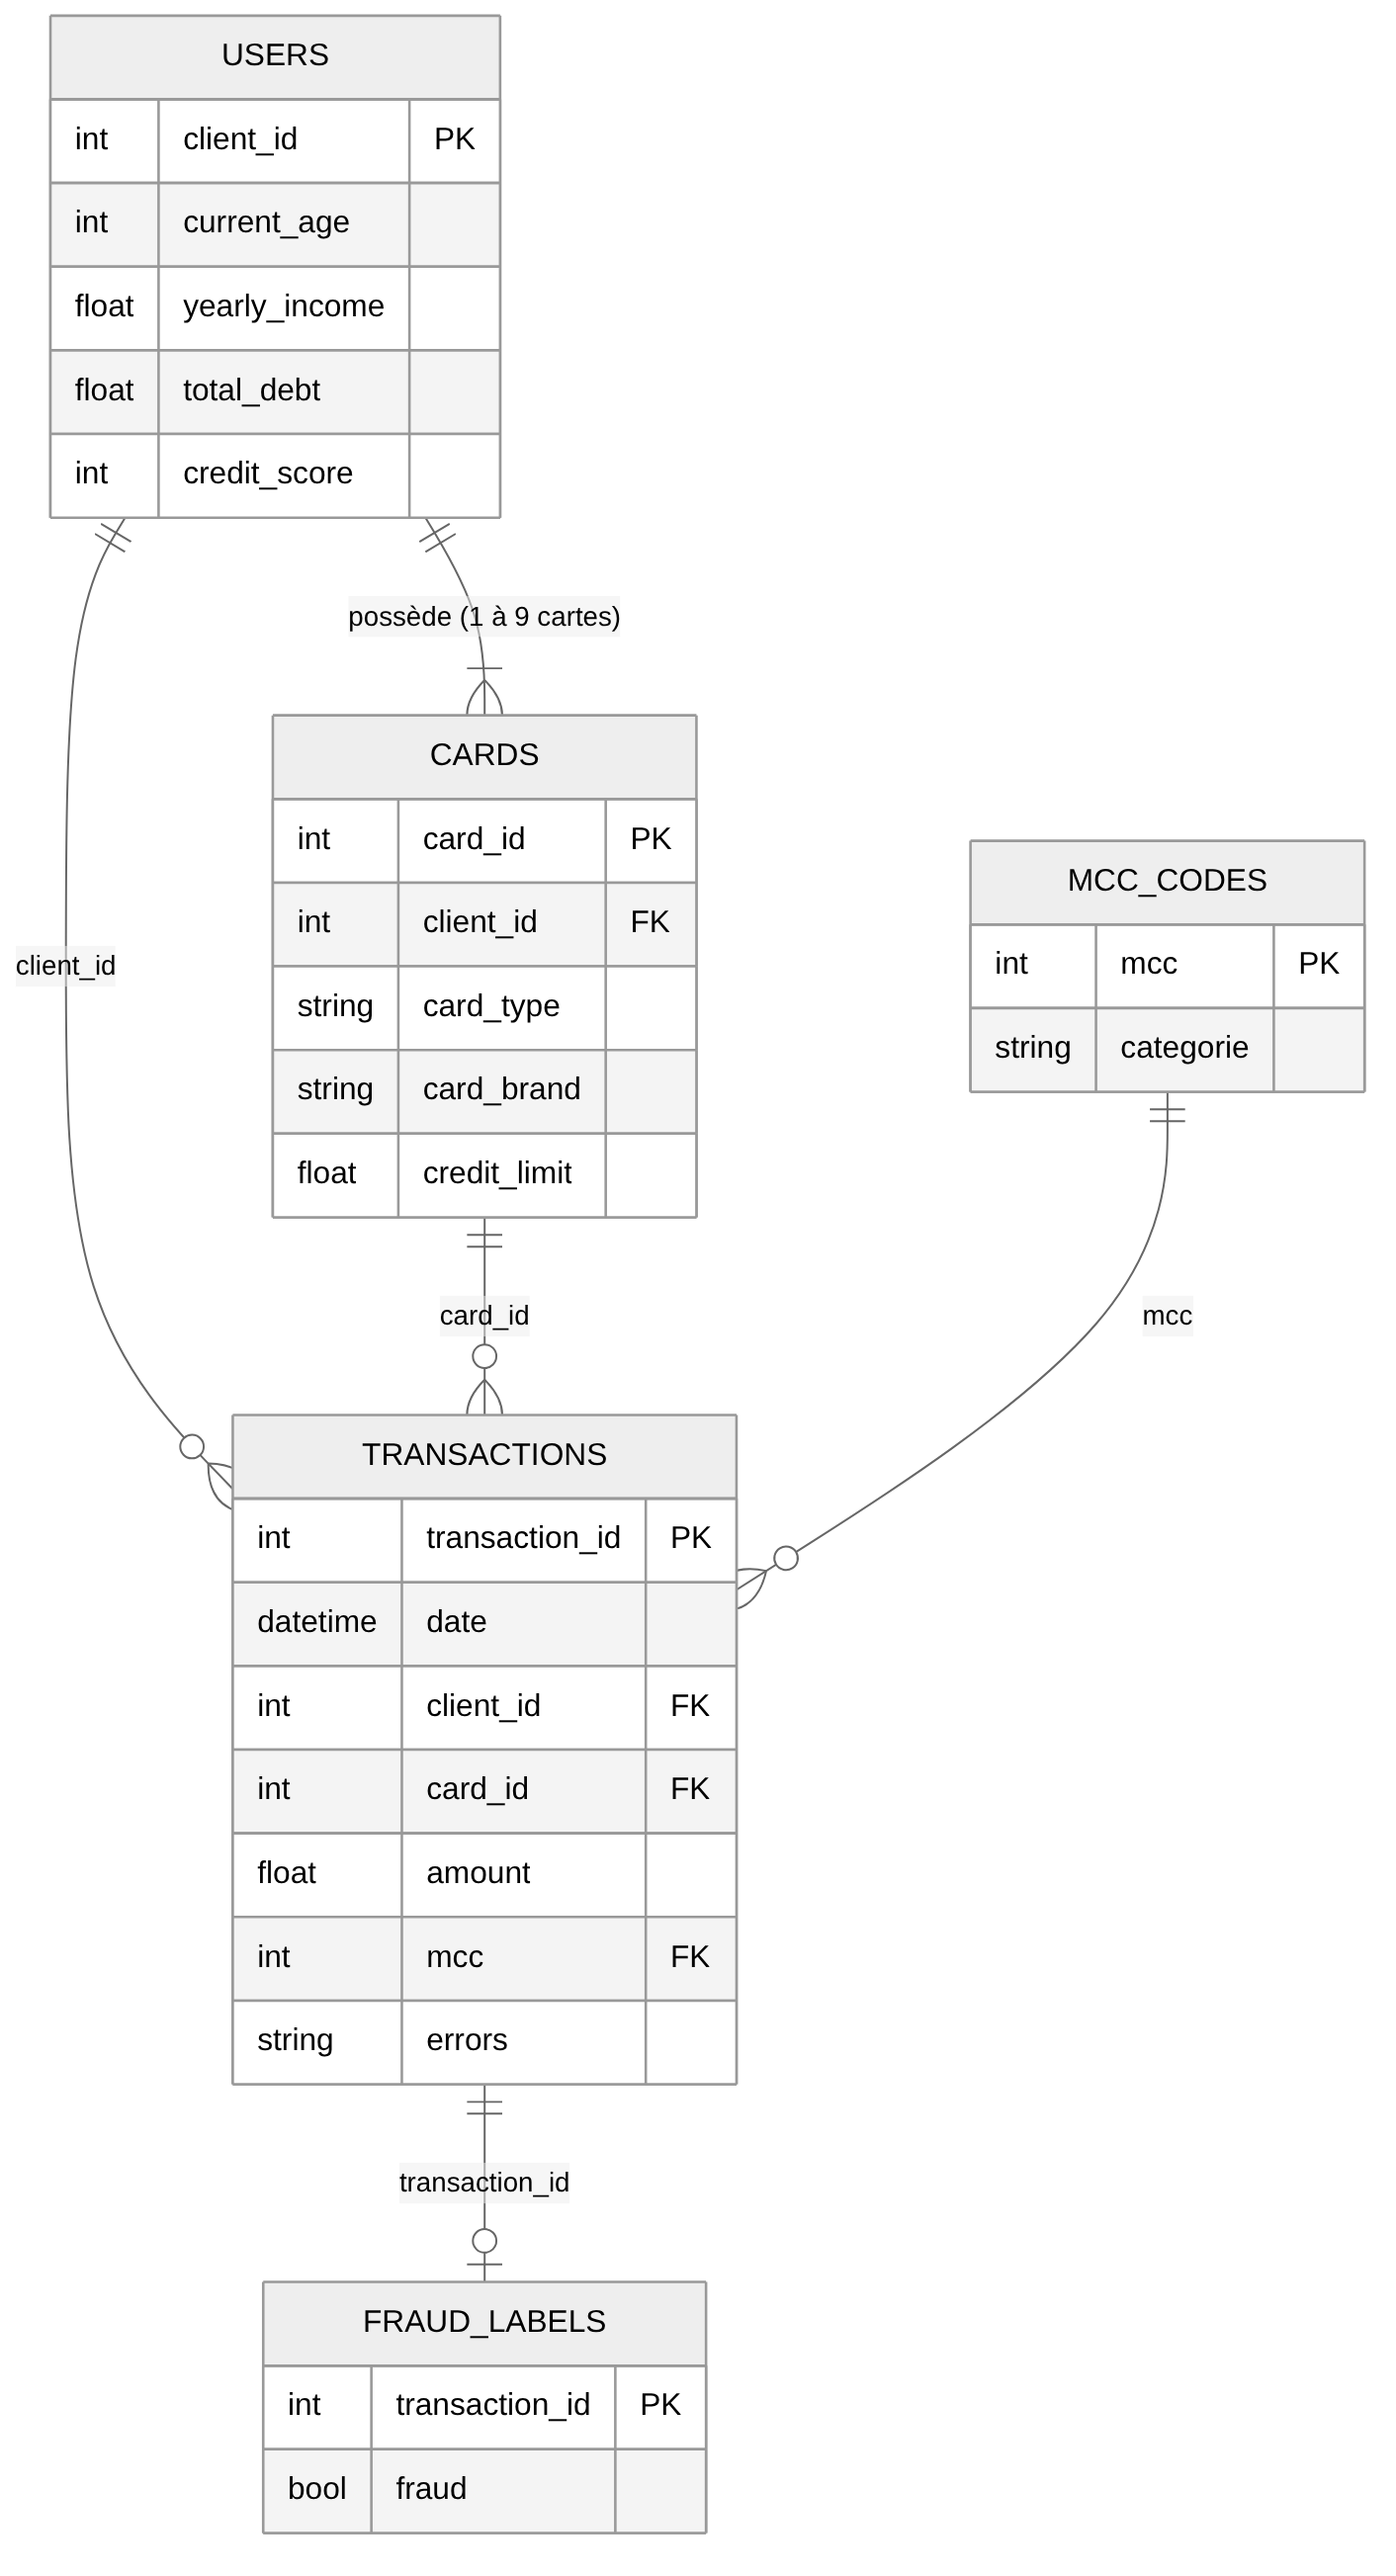

In [8]:
cles = [("users", "client_id"), ("cards", "card_id"), ("transactions", "transaction_id"),
        ("mcc_codes", "mcc"), ("fraud_labels", "transaction_id")]
verif_cles = pd.DataFrame([{"table": t, "cle": k, "lignes": len(TABLES_RAW[t]),
                            "valeurs_distinctes": TABLES_RAW[t][k].nunique(),
                            "cle_unique": TABLES_RAW[t][k].is_unique} for t, k in cles])
verif_cles

,table,cle,lignes,valeurs_distinctes,cle_unique
0,users,client_id,2000,2000,True
1,cards,card_id,6146,6146,True
2,transactions,transaction_id,13305915,13305915,True
3,mcc_codes,mcc,109,109,True
4,fraud_labels,transaction_id,8914963,8914963,True


In [9]:
u, c, t = users_raw, cards_raw, tx_raw
cartes_par_client = c.groupby("client_id").size()
tx_par_carte = t.groupby("card_id").size()
tx_par_client = t.groupby("client_id").size()

cardinalites = pd.DataFrame([
    {"lien": "client → cartes", "type": "1 – N (1 à 9)", "min": cartes_par_client.min(),
     "mediane": cartes_par_client.median(), "max": cartes_par_client.max(),
     "sans_lien": int((~u.client_id.isin(c.client_id)).sum()), "commentaire": "clients sans carte"},
    {"lien": "carte → transactions", "type": "1 – N (0 possible)", "min": tx_par_carte.min(),
     "mediane": tx_par_carte.median(), "max": tx_par_carte.max(),
     "sans_lien": int((~c.card_id.isin(t.card_id)).sum()), "commentaire": "cartes jamais utilisées"},
    {"lien": "client → transactions", "type": "1 – N (0 possible)", "min": tx_par_client.min(),
     "mediane": tx_par_client.median(), "max": tx_par_client.max(),
     "sans_lien": int((~u.client_id.isin(t.client_id)).sum()), "commentaire": "clients sans transaction"},
    {"lien": "catégorie MCC → transactions", "type": "1 – N", "min": None, "mediane": None, "max": None,
     "sans_lien": int((~mcc_raw.mcc.astype(int).isin(t.mcc)).sum()), "commentaire": "codes MCC jamais utilisés"},
    {"lien": "transaction → étiquette", "type": "1 – 0..1", "min": None, "mediane": None, "max": None,
     "sans_lien": int((~t.transaction_id.isin(labels_raw.transaction_id.astype("int64"))).sum()),
     "commentaire": "transactions sans étiquette"},
])
cardinalites

,lien,type,min,mediane,max,sans_lien,commentaire
0,client → cartes,1 – N (1 à 9),1.0,3.0,9.0,0,clients sans carte
1,carte → transactions,1 – N (0 possible),1.0,2558.0,31552.0,2075,cartes jamais utilisées
2,client → transactions,1 – N (0 possible),760.0,9832.0,48479.0,781,clients sans transaction
3,catégorie MCC → transactions,1 – N,NaN,NaN,NaN,0,codes MCC jamais utilisés
4,transaction → étiquette,1 – 0..1,NaN,NaN,NaN,4390952,transactions sans étiquette


In [10]:
# Cohérence 1 : le client d'une transaction est-il bien le titulaire de la carte utilisée ?
paires = t[["card_id", "client_id"]].drop_duplicates()
paires = paires.merge(c[["card_id", "client_id"]].rename(columns={"client_id": "titulaire"}),
                      on="card_id", how="left", validate="many_to_one")
n_incoh = int((paires.client_id != paires.titulaire).sum())
print(f"Paires (carte, client) distinctes dans les transactions : {len(paires)}")
print(f"Transactions dont le client n'est pas le titulaire de la carte : {n_incoh}")

# Cohérence 2 : num_credit_cards (users) = nombre de cartes dans cards ?
ecart = u.set_index("client_id").num_credit_cards - cartes_par_client
print(f"Clients pour qui num_credit_cards ≠ nombre de cartes dans cards : {int((ecart != 0).sum())}")
journal("2.2", "transactions", "client_id", "Toujours égal au titulaire de card_id : colonne redondante mais cohérente",
        0, "Garder pour faciliter les jointures")
journal("2.2", "users", "num_credit_cards", "Égal au nombre de cartes de la table cards (redondance exacte)",
        0, "Garder (contrôle de cohérence)")

Paires (carte, client) distinctes dans les transactions : 4071
Transactions dont le client n'est pas le titulaire de la carte : 0
Clients pour qui num_credit_cards ≠ nombre de cartes dans cards : 0


In [11]:
# Test des jointures prévues à la tâche 2.8 (sur les colonnes clés seulement, pour économiser la mémoire)
base = t[["transaction_id", "card_id", "client_id", "mcc"]]
n0 = len(base)
essais = {}
j = base.merge(c[["card_id", "card_type"]], on="card_id", how="left", validate="many_to_one")
essais["transactions ⟕ cards (card_id)"] = len(j)
j = base.merge(u[["client_id", "current_age"]], on="client_id", how="left", validate="many_to_one")
essais["transactions ⟕ users (client_id)"] = len(j)
j = base.merge(mcc_raw.assign(mcc=mcc_raw.mcc.astype(int)), on="mcc", how="left", validate="many_to_one")
essais["transactions ⟕ mcc_codes (mcc)"] = len(j)
j = base.merge(labels_raw.assign(transaction_id=labels_raw.transaction_id.astype("int64")),
               on="transaction_id", how="left", validate="one_to_one")
essais["transactions ⟕ fraud_labels (transaction_id)"] = len(j)
del j, base
pd.DataFrame([{"jointure (how='left')": k, "lignes_avant": n0, "lignes_apres": v,
               "lignes_multipliees": v != n0} for k, v in essais.items()])

,jointure (how='left'),lignes_avant,lignes_apres,lignes_multipliees
0,transactions ⟕ cards (card_id),13305915,13305915,False
1,transactions ⟕ users (client_id),13305915,13305915,False
2,transactions ⟕ mcc_codes (mcc),13305915,13305915,False
3,transactions ⟕ fraud_labels (transaction_id),13305915,13305915,False


**À retenir (2.2)**
- Les 5 clés primaires sont **uniques** (injectives).
- `users` 1 – N `cards` : chaque client a de 1 à 9 cartes, et `num_credit_cards` est exactement ce nombre.
- `cards` 1 – N `transactions` : 2 075 cartes n'ont aucune transaction.
- `users` 1 – N `transactions` : 781 clients n'ont aucune transaction.
- `transactions` 1 – 0..1 `fraud_labels` : seule une partie des transactions est étiquetée.
- Le `client_id` d'une transaction est **toujours** le titulaire de la carte. Il n'y a aucune incohérence.
- Les jointures `left` sur ces clés **ne multiplient pas les lignes**. La fusion de la tâche 2.8 est donc sûre.

---
# Tâche 2.3 – Conversion des formats (KAN-12)

Selon la semaine 07, *la statistique dépend de l'échelle de mesure*. Chaque variable reçoit donc un type adapté :

| Variable | Avant | Après |
|---|---|---|
| Montants | texte `"$-77.00"` | `float` |
| Dates | texte | `datetime64` (`MM/AAAA` → 1er jour du mois) |
| Codes postaux | `58523.0` (décimal) | texte à 5 chiffres (`"02108"`) |
| Oui / non | `YES/NO`, `Yes/No` | `bool` |
| Variables qualitatives répétées | texte | `category` (moins de mémoire) |
| Numéro de carte, CVV | entier | texte : ce sont des identifiants, pas des quantités |

Pour chaque conversion, on mesure le **taux de validité** $V_j = \frac{1}{n}\sum_i \mathbf{1}\{x_{ij} \in D_j\}$ : la part des valeurs non manquantes converties sans erreur.

In [12]:
RAPPORT_TYPES = []

def noter(table, var, avant, apres, regle, s_avant, s_apres):
    n_obs = int(s_avant.notna().sum())
    echecs = int((s_avant.notna() & s_apres.isna()).sum())
    RAPPORT_TYPES.append({"table": table, "variable": var, "type_avant": avant, "type_apres": str(s_apres.dtype),
                          "regle": regle, "valeurs_non_converties": echecs,
                          "validite_Vj": f"{100 * (1 - echecs / n_obs):.2f} %" if n_obs else "—"})

def montant(s):
    # "$-77.00" -> -77.0 ; une valeur au mauvais format devient NaN (comptée comme non convertie)
    return pd.to_numeric(s.astype("string").str.replace("$", "", regex=False), errors="coerce").astype("float64")

def oui_non(s, oui):
    return s.map({oui: True}).fillna(False).astype(bool).where(s.notna())

mem_avant = {k: v.memory_usage(deep=True).sum() / 1e6 for k, v in
             {"users": users_raw, "cards": cards_raw, "transactions": tx_raw,
              "fraud_labels": labels_raw, "mcc_codes": mcc_raw}.items()}

In [13]:
# ---- users
users = users_raw.copy()
for col in ["per_capita_income", "yearly_income", "total_debt"]:
    users[col] = montant(users_raw[col])
    noter("users", col, "texte", "", "retirer « $ » puis float", users_raw[col], users[col])
users["gender"] = users_raw["gender"].astype("category")
noter("users", "gender", "texte", "", "category", users_raw["gender"], users["gender"])

# ---- cards
cards = cards_raw.copy()
cards["credit_limit"] = montant(cards_raw["credit_limit"])
noter("cards", "credit_limit", "texte", "", "retirer « $ » puis float", cards_raw["credit_limit"], cards["credit_limit"])
for col in ["expires", "acct_open_date"]:
    cards[col] = pd.to_datetime(cards_raw[col], format="%m/%Y", errors="coerce")
    noter("cards", col, "texte MM/AAAA", "", "datetime (1er du mois)", cards_raw[col], cards[col])
cards["has_chip"] = oui_non(cards_raw["has_chip"], "YES")
noter("cards", "has_chip", "texte YES/NO", "", "bool", cards_raw["has_chip"], cards["has_chip"])
cards["card_on_dark_web"] = oui_non(cards_raw["card_on_dark_web"], "Yes")
noter("cards", "card_on_dark_web", "texte Yes/No", "", "bool", cards_raw["card_on_dark_web"], cards["card_on_dark_web"])
for col in ["card_brand", "card_type"]:
    cards[col] = cards_raw[col].astype("category")
    noter("cards", col, "texte", "", "category", cards_raw[col], cards[col])
cards["card_number"] = cards_raw["card_number"].astype(str)
noter("cards", "card_number", "entier", "", "texte (identifiant)", cards_raw["card_number"], cards["card_number"])
cards["cvv"] = cards_raw["cvv"].astype(str).str.zfill(3)
noter("cards", "cvv", "entier", "", "texte à 3 chiffres (identifiant)", cards_raw["cvv"], cards["cvv"])

# ---- mcc_codes et fraud_labels
mcc_codes = mcc_raw.assign(mcc=pd.to_numeric(mcc_raw["mcc"], errors="coerce").astype("int64"))
noter("mcc_codes", "mcc", "texte", "", "entier (comme dans transactions)", mcc_raw["mcc"], mcc_codes["mcc"])
fraud_labels = pd.DataFrame({
    "transaction_id": pd.to_numeric(labels_raw["transaction_id"], errors="coerce").astype("int64"),
    "fraud": oui_non(labels_raw["fraud"], "Yes")})
noter("fraud_labels", "transaction_id", "texte", "", "entier", labels_raw["transaction_id"], fraud_labels["transaction_id"])
noter("fraud_labels", "fraud", "texte Yes/No", "", "bool", labels_raw["fraud"], fraud_labels["fraud"])

In [14]:
# ---- transactions (13,3 M lignes) : conversion colonne par colonne
t0 = time.time()
tx = pd.DataFrame({"transaction_id": tx_raw["transaction_id"]})
tx["date"] = pd.to_datetime(tx_raw["date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
noter("transactions", "date", "texte", "", "datetime", tx_raw["date"], tx["date"])
tx["client_id"] = tx_raw["client_id"]
tx["card_id"] = tx_raw["card_id"]
tx["amount"] = montant(tx_raw["amount"])
noter("transactions", "amount", "texte", "", "retirer « $ » puis float", tx_raw["amount"], tx["amount"])
for col in ["use_chip", "merchant_city", "merchant_state"]:
    tx[col] = tx_raw[col].astype("category")
    noter("transactions", col, "texte", "", "category", tx_raw[col], tx[col])
tx["merchant_id"] = tx_raw["merchant_id"]

# Code postal : 2108.0 -> "02108" (les zéros de tête avaient été perdus à la lecture en nombre)
z = tx_raw["zip"]
entier = z.notna() & (z % 1 == 0) & z.between(0, 99999)
tx["zip"] = z.where(entier).astype("Int64").astype("string").str.zfill(5).astype("category")
noter("transactions", "zip", "décimal (58523.0)", "", "texte à 5 chiffres", z, tx["zip"])
print(f"Codes postaux qui avaient perdu leur zéro de tête : {nb(int((z < 10000).sum()))}")

tx["mcc"] = tx_raw["mcc"]
tx["errors"] = tx_raw["errors"].astype("category")
noter("transactions", "errors", "texte", "", "category (valeurs multiples gardées)", tx_raw["errors"], tx["errors"])
print(f"Conversion des transactions : {time.time() - t0:.0f} s")

Codes postaux qui avaient perdu leur zéro de tête : 803 000


Conversion des transactions : 30 s


In [15]:
rapport_types = pd.DataFrame(RAPPORT_TYPES)
for table, df in {"users": users, "cards": cards, "transactions": tx,
                  "fraud_labels": fraud_labels, "mcc_codes": mcc_codes}.items():
    m = rapport_types.table == table
    rapport_types.loc[m, "type_apres"] = rapport_types.loc[m, "variable"].map(lambda v: str(df[v].dtype))
display(rapport_types)

memoire = pd.DataFrame([{"table": k, "memoire_avant_Mo": round(mem_avant[k], 1),
                         "memoire_apres_Mo": round(v.memory_usage(deep=True).sum() / 1e6, 1)}
                        for k, v in {"users": users, "cards": cards, "transactions": tx,
                                     "fraud_labels": fraud_labels, "mcc_codes": mcc_codes}.items()])
memoire

,table,variable,type_avant,type_apres,regle,valeurs_non_converties,validite_Vj
0,users,per_capita_income,texte,float64,retirer « $ » puis float,0,100.00 %
1,users,yearly_income,texte,float64,retirer « $ » puis float,0,100.00 %
2,users,total_debt,texte,float64,retirer « $ » puis float,0,100.00 %
3,users,gender,texte,category,category,0,100.00 %
4,cards,credit_limit,texte,float64,retirer « $ » puis float,0,100.00 %
5,cards,expires,texte MM/AAAA,datetime64[us],datetime (1er du mois),0,100.00 %
6,cards,acct_open_date,texte MM/AAAA,datetime64[us],datetime (1er du mois),0,100.00 %
7,cards,has_chip,texte YES/NO,bool,bool,0,100.00 %
8,cards,card_on_dark_web,texte Yes/No,bool,bool,0,100.00 %
9,cards,card_brand,texte,category,category,0,100.00 %


,table,memoire_avant_Mo,memoire_apres_Mo
0,users,0.3,0.2
1,cards,0.9,0.6
2,transactions,1977.3,852.1
3,fraud_labels,230.4,80.2
4,mcc_codes,0.0,0.0


In [16]:
# Les fichiers bruts restent intacts : on enregistre les versions converties à part (parquet garde les types)
for nom, df in {"users": users, "cards": cards, "transactions": tx,
                "fraud_labels": fraud_labels, "mcc_codes": mcc_codes}.items():
    df.to_parquet(INTERIM_DIR / f"{nom}.parquet", index=False)
print("Fichiers enregistrés :", sorted(p.name for p in INTERIM_DIR.glob("*.parquet")))

# Les données brutes ne servent plus : on libère la mémoire
del tx_raw, labels_raw
TABLES_RAW.clear()
import gc; gc.collect()
try:                                   # rendre au système la mémoire gardée par pyarrow
    import pyarrow as pa
    pa.default_memory_pool().release_unused()
except Exception:
    pass

Fichiers enregistrés : ['cards.parquet', 'fraud_labels.parquet', 'mcc_codes.parquet', 'transactions.parquet', 'users.parquet']


**À retenir (2.3)**
- Toutes les conversions ont un taux de validité de **100 %** : aucune valeur n'avait un format inattendu.
- Plus de 800 000 codes postaux avaient perdu leur **zéro de tête** (par ex. `2108.0` au lieu de `02108`). Ils sont corrigés.
- Les types `category` divisent la mémoire des transactions par plus de 2.
- Les données converties sont enregistrées dans `data/interim/*.parquet`. Les tâches suivantes (2.7, 2.8) repartent de là sans relire le CSV.

---
# Tâche 2.4 – Valeurs manquantes (KAN-13)

On construit la matrice indicatrice $R = (r_{ij})$, où $r_{ij} = 1$ si $x_{ij}$ est manquante. On en tire :
- le nombre de manquants $m_j = \sum_i r_{ij}$ ;
- le taux de manquants $\tau_j = m_j / n$ ;
- le taux de complétude $C_j = 1 - \tau_j$.

Ensuite, on distingue trois cas (semaine 07) :
1. les **vrais manquants** ;
2. les **valeurs non applicables** : un champ vide parce qu'il n'a pas de sens pour la ligne ;
3. les **manquants déguisés** : des codes comme `0`, `-999` ou `"inconnu"` qui cachent une absence.

In [17]:
lignes = []
for table, df in {"users": users, "cards": cards, "transactions": tx,
                  "fraud_labels": fraud_labels, "mcc_codes": mcc_codes}.items():
    R = df.isna()                      # matrice indicatrice des manquants
    m = R.sum()
    for col in df.columns:
        lignes.append({"table": table, "variable": col, "n": len(df), "m_j": int(m[col]),
                       "tau_j_%": round(100 * m[col] / len(df), 2),
                       "completude_Cj_%": round(100 * (1 - m[col] / len(df)), 2)})
manquants = pd.DataFrame(lignes)
print("Variables avec au moins une valeur manquante :")
manquants[manquants.m_j > 0]

Variables avec au moins une valeur manquante :


,table,variable,n,m_j,tau_j_%,completude_Cj_%
34,transactions,merchant_state,13305915,1563700,11.75,88.25
36,transactions,zip,13305915,1652706,12.42,87.58
38,transactions,errors,13305915,13094522,98.41,1.59


In [18]:
# Les manquants sont-ils de vrais manquants ? On croise avec merchant_city et l'État ou pays.
en_ligne = tx["merchant_city"] == "ONLINE"
ETATS_US = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY "
               "NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
etranger = tx["merchant_state"].notna() & ~tx["merchant_state"].astype("string").isin(ETATS_US).fillna(False)

etat_na, zip_na = tx["merchant_state"].isna(), tx["zip"].isna()
explication = pd.DataFrame({
    "cas": ["merchant_state manquant", "  dont transaction en ligne (ONLINE)",
            "zip manquant", "  dont transaction en ligne (ONLINE)", "  dont commerçant à l'étranger",
            "  dont autre cas (vrai manquant)"],
    "n": [etat_na.sum(), (etat_na & en_ligne).sum(),
          zip_na.sum(), (zip_na & en_ligne).sum(), (zip_na & etranger).sum(),
          (zip_na & ~en_ligne & ~etranger).sum()]})
explication["n"] = explication["n"].astype(int)
display(explication)

print(f"Commerçants à l'étranger : {nb(etranger.sum())} transactions, "
      f"{tx.loc[etranger, 'merchant_state'].nunique()} pays")
display(tx.loc[etranger, "merchant_state"].value_counts().head(8).rename("transactions"))

,cas,n
0,merchant_state manquant,1563700
1,dont transaction en ligne (ONLINE),1563700
2,zip manquant,1652706
3,dont transaction en ligne (ONLINE),1563700
4,dont commerçant à l'étranger,89006
5,dont autre cas (vrai manquant),0


Commerçants à l'étranger : 89 012 transactions, 148 pays


merchant_state
Mexico            27401
Canada            10647
Italy              7081
United Kingdom     4482
Germany            3025
China              2908
France             2836
Japan              2107
Name: transactions, dtype: int64

In [19]:
# errors : un vide veut dire « aucune erreur », ce n'est pas une valeur manquante
n_err = int(tx["errors"].notna().sum())
print(f"Transactions avec au moins une erreur : {nb(n_err)} ({pct(n_err, len(tx))})")
print(f"dont avec plusieurs erreurs (virgule) : {nb(int(tx['errors'].astype('string').str.contains(',').sum()))}")

journal("2.4", "transactions", "merchant_state", "Vide = transaction en ligne (non applicable)",
        int(etat_na.sum()), "Ne pas imputer ; recoder en « ONLINE »")
journal("2.4", "transactions", "zip", "Vide = en ligne ou à l'étranger (non applicable), 0 vrai manquant",
        int(zip_na.sum()), "Ne pas imputer ; garder vide ou « NA_ETRANGER »")
journal("2.4", "transactions", "errors", "Vide = aucune erreur (non manquant)",
        int(len(tx) - n_err), "Recoder en « Aucune » + indicateurs par type d'erreur (2.10)")

Transactions avec au moins une erreur : 211 393 (1.59 %)


dont avec plusieurs erreurs (virgule) : 941


### Manquants déguisés

On cherche les valeurs qui *ressemblent* à des données mais qui peuvent cacher une absence : `0`, codes spéciaux, ou textes comme `unknown`, `N/A` et `none`.

In [20]:
textes_suspects = {"unknown", "n/a", "na", "none", "null", "", "-", "?", "inconnu"}
for nom, df in {"users": users, "cards": cards, "transactions": tx}.items():
    for col in df.select_dtypes(include=["object", "string", "category"]).columns:
        vals = df[col].dropna().astype("string").str.strip().str.lower()
        n = int(vals.isin(textes_suspects).sum())
        if n:
            print(f"{nom}.{col} : {n} valeurs textuelles suspectes")
print("Recherche des textes suspects terminée.")

deguises = pd.DataFrame([
    {"table": "users", "variable": "per_capita_income", "valeur": "0 $",
     "n": int((users.per_capita_income == 0).sum()),
     "lecture": "Revenu par habitant d'une zone nul : impossible → manquant déguisé probable"},
    {"table": "users", "variable": "yearly_income", "valeur": "< 1 000 $",
     "n": int((users.yearly_income < 1000).sum()),
     "lecture": "Revenus annuels très faibles (min 1 $) : à vérifier"},
    {"table": "users", "variable": "total_debt", "valeur": "0 $",
     "n": int((users.total_debt == 0).sum()),
     "lecture": "Aucune dette : plausible (pas un manquant)"},
    {"table": "cards", "variable": "credit_limit", "valeur": "0 $",
     "n": int((cards.credit_limit == 0).sum()),
     "lecture": "Limite nulle : manquant déguisé possible (voir le type de carte)"},
    {"table": "transactions", "variable": "amount", "valeur": "0,00 $",
     "n": int((tx.amount == 0).sum()),
     "lecture": "Transaction de 0 $ : vérification de carte possible, à examiner"},
    {"table": "transactions", "variable": "merchant_city", "valeur": "ONLINE",
     "n": int(en_ligne.sum()),
     "lecture": "Pseudo-ville pour les achats en ligne (non applicable, pas une erreur)"},
])
display(deguises)
display(Markdown("**Cartes à limite de crédit nulle, par type :**"))
display(cards.loc[cards.credit_limit == 0, "card_type"].value_counts().rename("cartes"))
display(Markdown("**Clients avec un revenu par habitant nul :**"))
display(users.loc[users.per_capita_income == 0, ["client_id", "current_age", "yearly_income", "total_debt", "credit_score"]])

journal("2.4", "users", "per_capita_income", "Valeur 0 = manquant déguisé probable",
        int((users.per_capita_income == 0).sum()), "Recoder en NaN puis imputer par la médiane (variable asymétrique)")
journal("2.4", "cards", "credit_limit", "Valeur 0 = manquant déguisé possible",
        int((cards.credit_limit == 0).sum()), "Recoder en NaN, imputer par la médiane du même card_type")
journal("2.4", "transactions", "amount", "Montant exactement 0 $",
        int((tx.amount == 0).sum()), "Garder ; signaler (test de carte possible)")

Recherche des textes suspects terminée.


,table,variable,valeur,n,lecture
0,users,per_capita_income,0 $,15,Revenu par habitant d'une zone nul : impossible → manquant déguisé probable
1,users,yearly_income,< 1 000 $,8,Revenus annuels très faibles (min 1 $) : à vérifier
2,users,total_debt,0 $,102,Aucune dette : plausible (pas un manquant)
3,cards,credit_limit,0 $,31,Limite nulle : manquant déguisé possible (voir le type de carte)
4,transactions,amount,"0,00 $",10639,"Transaction de 0 $ : vérification de carte possible, à examiner"
5,transactions,merchant_city,ONLINE,1563700,"Pseudo-ville pour les achats en ligne (non applicable, pas une erreur)"


**Cartes à limite de crédit nulle, par type :**

card_type
Credit             26
Debit               3
Debit (Prepaid)     2
Name: cartes, dtype: int64

**Clients avec un revenu par habitant nul :**

,client_id,current_age,yearly_income,total_debt,credit_score
246,1828,50,2466.0,5521.0,711
662,1016,41,553.0,740.0,719
741,82,22,2026.0,1417.0,779
751,1151,53,920.0,1914.0,788
764,1942,77,1.0,0.0,673
993,1481,72,2422.0,810.0,632
1068,1663,24,2370.0,4397.0,581
1100,1530,64,1785.0,2892.0,732
1166,1985,50,1426.0,3154.0,680
1213,608,32,2365.0,0.0,769


### Étiquette de fraude : le principal manquant

`fraud_labels.json` couvre 8 914 963 transactions sur 13 305 915. Il manque donc l'étiquette pour **un tiers** des transactions. On cherche le **mécanisme** en jeu (Rubin, 1976) :
- **MCAR** : l'absence ne dépend de rien ;
- **MAR** : l'absence dépend de variables observées.

Si le taux d'étiquetage est le même dans tous les groupes observés, l'hypothèse MCAR est plausible.

Transactions sans étiquette : 4 390 952 (33.00 %)


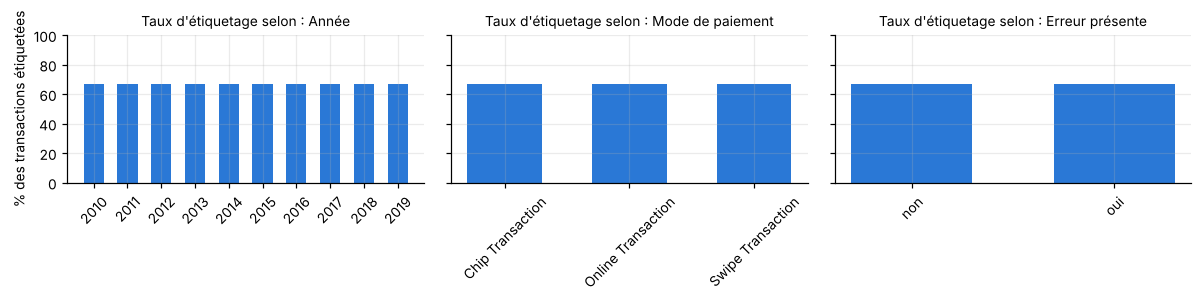

Parmi les transactions étiquetées : 13 332 fraudes = 0.150 % (classes très déséquilibrées)


In [21]:
etiq = tx["transaction_id"].isin(fraud_labels["transaction_id"])
n_sans = int((~etiq).sum())
print(f"Transactions sans étiquette : {nb(n_sans)} ({pct(n_sans, len(tx))})")

fig, axes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, (titre, g) in zip(axes, [("Année", tx["date"].dt.year), ("Mode de paiement", tx["use_chip"]),
                                  ("Erreur présente", tx["errors"].notna().map({True: "oui", False: "non"}))]):
    taux = etiq.groupby(g, observed=True).mean() * 100
    ax.bar(taux.index.astype(str), taux.values, color=BLEU, width=0.6)
    ax.set_title(f"Taux d'étiquetage selon : {titre}", fontsize=9)
    ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("% des transactions étiquetées")
plt.tight_layout(); plt.show()

taux_fraude = fraud_labels["fraud"].mean()
print(f"Parmi les transactions étiquetées : {nb(fraud_labels.fraud.sum())} fraudes "
      f"= {100 * taux_fraude:.3f} % (classes très déséquilibrées)")
journal("2.4", "fraud_labels", "fraud", "33 % des transactions sans étiquette ; taux constant (~67 %) selon année, mode, erreurs → MCAR plausible",
        n_sans, "Ne jamais imputer la cible ; analyses de fraude sur le sous-ensemble étiqueté (cas disponibles)")

### Pourquoi ne pas supprimer les lignes incomplètes ?

Si les absences sont indépendantes, le nombre de lignes complètes attendu est $n_{complet} \approx n \prod_j (1-\tau_j)$ (semaine 07).

Ici, les « manquants » des transactions sont presque tous **non applicables**. Supprimer les cas incomplets ferait disparaître **tous les achats en ligne et tous les achats à l'étranger**. Cela créerait un biais grave, car ce sont justement des contextes à risque de fraude.

In [22]:
n = len(tx)
cols_na = ["merchant_state", "zip"]
attendu_indep = n * np.prod([1 - tx[c].isna().mean() for c in cols_na])
reel = int(tx[cols_na].notna().all(axis=1).sum())
print(f"Lignes complètes (merchant_state et zip) : réel = {nb(reel)} ; formule d'indépendance = {nb(round(attendu_indep))}")
print(f"→ supprimer les cas incomplets retirerait {nb(n - reel)} transactions ({pct(n - reel, n)}),",
      "dont 100 % des achats en ligne.")
print("Les absences ne sont pas indépendantes (elles viennent ensemble), donc la formule ne s'applique pas.")

Lignes complètes (merchant_state et zip) : réel = 11 653 209 ; formule d'indépendance = 10 283 734
→ supprimer les cas incomplets retirerait 1 652 706 transactions (12.42 %), dont 100 % des achats en ligne.
Les absences ne sont pas indépendantes (elles viennent ensemble), donc la formule ne s'applique pas.


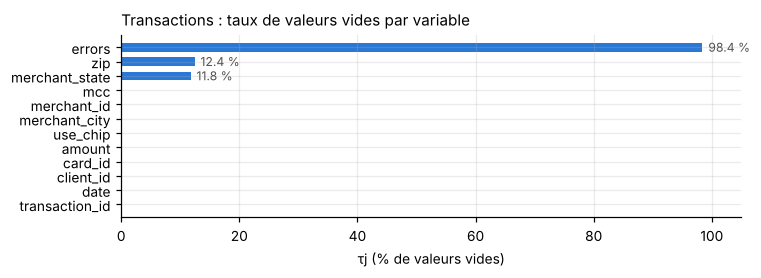

In [23]:
fig, ax = plt.subplots(figsize=(7, 2.6))
mt = manquants[(manquants.table == "transactions")].set_index("variable")["tau_j_%"].sort_values()
ax.barh(mt.index, mt.values, color=[BLEU if v > 0 else "#cfd3d8" for v in mt.values], height=0.6)
for y, v in enumerate(mt.values):
    if v > 0:
        ax.text(v + 1, y, f"{v:.1f} %", va="center", fontsize=8, color=GRIS)
ax.set_xlim(0, 105); ax.set_xlabel("τj (% de valeurs vides)")
ax.set_title("Transactions : taux de valeurs vides par variable", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**À retenir (2.4)**
- `users`, `cards`, `mcc_codes` : **aucune** cellule vide.
- `transactions` : les vides de `merchant_state` (11,8 %) et de `zip` (12,4 %) sont des valeurs **non applicables** (achats en ligne ou à l'étranger). On compte **0 vrai manquant**.
- Dans `errors`, un vide (98,4 %) veut dire « aucune erreur ». Ce n'est pas un manquant.
- **Manquants déguisés** à traiter en 2.7 :
  - `per_capita_income = 0` (15 clients) ;
  - `credit_limit = 0` (31 cartes) ;
  - des revenus annuels très faibles, à examiner.
- **Étiquette de fraude** : 33 % des transactions n'en ont pas. Le taux est constant selon l'année, le mode de paiement et les erreurs, donc l'hypothèse **MCAR** est plausible. Parmi les transactions étiquetées, la fraude représente seulement **0,15 %**.

---
# Tâche 2.5 – Doublons et identifiants sans correspondance (KAN-14)

Définitions (semaine 07) :
- **doublon complet** : deux lignes identiques sur toutes les colonnes ;
- **doublon partiel** : deux lignes identiques sur un sous-ensemble de colonnes $K$ ;
- **identifiant orphelin** : une clé étrangère qui ne correspond à aucune ligne de la table liée (voir aussi la semaine 08 sur les jointures).

In [24]:
def masque_doublons(df, cols, keep="first"):
    # 13,3 M lignes : df.duplicated() sur toutes les colonnes demande trop de mémoire.
    # 1) on résume chaque ligne par une empreinte (hash) de 64 bits ; 2) on vérifie exactement les lignes candidates.
    h = pd.util.hash_pandas_object(df[cols], index=False)
    candidats = h.duplicated(keep=False)
    m = pd.Series(False, index=df.index)
    if candidats.any():
        m[candidats] = df.loc[candidats, cols].duplicated(keep=keep)
    return m

doublons = []
for nom, df, cle in [("users", users, "client_id"), ("cards", cards, "card_id"),
                     ("transactions", tx, "transaction_id"), ("fraud_labels", fraud_labels, "transaction_id"),
                     ("mcc_codes", mcc_codes, "mcc")]:
    autres = [c for c in df.columns if c != cle]
    doublons.append({"table": nom, "lignes": len(df),
                     "doublons_complets": int(masque_doublons(df, list(df.columns)).sum()),
                     "cle_dupliquee": int(df[cle].duplicated().sum()),
                     # sans objet pour une table qui n'a qu'une seule autre colonne (oui/non, libellé)
                     "doublons_hors_identifiant": int(masque_doublons(df, autres).sum()) if len(autres) > 1 else None})
doublons = pd.DataFrame(doublons)
display(doublons)

lib = mcc_codes[mcc_codes.categorie.duplicated(keep=False)]
display(Markdown("**Libellé MCC porté par deux codes différents** (normal : deux codes officiels distincts)")); display(lib)

,table,lignes,doublons_complets,cle_dupliquee,doublons_hors_identifiant
0,users,2000,0,0,0.0
1,cards,6146,0,0,0.0
2,transactions,13305915,0,0,33.0
3,fraud_labels,8914963,0,0,NaN
4,mcc_codes,109,0,0,NaN


**Libellé MCC porté par deux codes différents** (normal : deux codes officiels distincts)

,mcc,categorie
33,3722,Passenger Railways
79,4112,Passenger Railways


Dans `transactions`, des lignes sont identiques sur tout sauf l'identifiant. On élargit la recherche à un doublon **partiel** sur la clé métier
$K$ = (`card_id`, `date`, `amount`, `merchant_id`) : même carte, même minute, même montant, même commerçant.

In [25]:
K = ["card_id", "date", "amount", "merchant_id"]
masque = masque_doublons(tx, K, keep=False)
partiels = tx[masque].sort_values(K)
en_trop = masque_doublons(tx, K, keep="first")
n_partiels = int(en_trop.sum())
print(f"Doublons partiels sur K : {n_partiels} lignes en trop ({masque.sum()} lignes concernées)")
display(partiels.head(10))

# En quoi les lignes d'un même groupe diffèrent-elles ?
diff = partiels.groupby(K, observed=True).agg(n=("transaction_id", "size"),
                                             errors_differents=("errors", lambda s: s.astype("string").nunique(dropna=False) > 1))
n_tentatives = int(diff.errors_differents.sum())
n_exacts = int((~diff.errors_differents).sum())
print(f"Groupes où les lignes diffèrent seulement par l'erreur (ex. « Bad PIN » puis réussite) : {n_tentatives}")
print(f"Groupes de lignes identiques (même erreur ou aucune) : {n_exacts}")

Doublons partiels sur K : 100 lignes en trop (200 lignes concernées)


,transaction_id,date,client_id,card_id,amount,use_chip,merchant_city,merchant_state,merchant_id,zip,mcc,errors
6546370,15439996,2014-12-25 11:08:00,641,14,80.0,Swipe Transaction,Upper Sandusky,OH,27092,43351,4829,NaN
6546371,15439995,2014-12-25 11:08:00,641,14,80.0,Swipe Transaction,Upper Sandusky,OH,27092,43351,4829,Bad PIN
6866739,15833249,2015-03-20 11:27:00,641,14,80.0,Chip Transaction,Upper Sandusky,OH,27092,43351,4829,Insufficient Balance
6866740,15833250,2015-03-20 11:27:00,641,14,80.0,Chip Transaction,Upper Sandusky,OH,27092,43351,4829,NaN
2462321,10452656,2011-12-12 16:26:00,153,107,120.0,Swipe Transaction,Prescott Valley,AZ,27092,86314,4829,Insufficient Balance
2462322,10452657,2011-12-12 16:26:00,153,107,120.0,Swipe Transaction,Prescott Valley,AZ,27092,86314,4829,Insufficient Balance
684283,8294600,2010-07-23 21:14:00,87,109,20.0,Swipe Transaction,Leander,TX,27092,78641,4829,Insufficient Balance
684284,8294601,2010-07-23 21:14:00,87,109,20.0,Swipe Transaction,Leander,TX,27092,78641,4829,NaN
5255132,13858638,2014-01-13 21:52:00,87,109,20.0,Swipe Transaction,Leander,TX,27092,78641,4829,NaN
5255133,13858637,2014-01-13 21:52:00,87,109,20.0,Swipe Transaction,Leander,TX,27092,78641,4829,Bad PIN


Groupes où les lignes diffèrent seulement par l'erreur (ex. « Bad PIN » puis réussite) : 67
Groupes de lignes identiques (même erreur ou aucune) : 33


In [26]:
# Biais d'un doublon sur la moyenne : x̄' - x̄ = (x_k - x̄)/(n+1)
moy_avec = tx["amount"].mean()
moy_sans = tx.loc[~en_trop, "amount"].mean()
print(f"Montant moyen avec doublons : {moy_avec:.4f} $ ; sans : {moy_sans:.4f} $ ; biais = {moy_avec - moy_sans:+.5f} $")
print("Avec n = 13,3 M, le biais sur la moyenne est négligeable. Il peut toutefois compter pour l'analyse par carte "
      "(une transaction répétée la même minute ressemble à une double débit, signal possible de fraude).")

# Users : adresses en double
adr = users[users.address.duplicated(keep=False)][["client_id", "address", "latitude", "longitude", "current_age", "gender"]]
display(Markdown("**Adresse présente deux fois dans `users` :**")); display(adr)
print("Coordonnées et âges différents : deux clients distincts (même nom de rue dans deux villes), pas un doublon.")

# Doublons approximatifs : la normalisation (casse, espaces) révèle-t-elle des variantes de villes ?
villes = tx["merchant_city"].cat.categories.to_series()
norm = villes.str.strip().str.lower()
print(f"Villes distinctes : {nb(villes.size)} ; après normalisation (casse, espaces) : {nb(norm.nunique())}")

journal("2.5", "transactions", "toutes sauf transaction_id", "Doublons exacts (même carte, minute, montant, commerçant, erreur)",
        n_exacts, "Vérifier puis supprimer, ou garder si double débit réel (à décider en équipe)")
journal("2.5", "transactions", "card_id+date+amount+merchant_id", "Nouvelle tentative après une erreur (même transaction, erreur différente)",
        n_tentatives, "Ne pas supprimer : c'est un comportement réel ; indicateur « tentative répétée » possible (2.9/2.10)")

Montant moyen avec doublons : 42.9760 $ ; sans : 42.9758 $ ; biais = +0.00027 $
Avec n = 13,3 M, le biais sur la moyenne est négligeable. Il peut toutefois compter pour l'analyse par carte (une transaction répétée la même minute ressemble à une double débit, signal possible de fraude).


**Adresse présente deux fois dans `users` :**

,client_id,address,latitude,longitude,current_age,gender
1411,960,506 Washington Lane,33.83,-117.85,29,Male
1535,1800,506 Washington Lane,37.48,-86.29,62,Male


Coordonnées et âges différents : deux clients distincts (même nom de rue dans deux villes), pas un doublon.
Villes distinctes : 12 492 ; après normalisation (casse, espaces) : 12 492


In [27]:
fk = [
    ("cards.client_id → users", cards.client_id, users.client_id),
    ("transactions.client_id → users", tx.client_id, users.client_id),
    ("transactions.card_id → cards", tx.card_id, cards.card_id),
    ("transactions.mcc → mcc_codes", tx.mcc, mcc_codes.mcc),
    ("fraud_labels.transaction_id → transactions", fraud_labels.transaction_id, tx.transaction_id),
]
orphelins = pd.DataFrame([{"cle_etrangere": nom, "valeurs": len(s), "orphelines": int((~s.isin(ref)).sum())}
                          for nom, s, ref in fk])
display(Markdown("**Clés étrangères sans correspondance (orphelines)**")); display(orphelins)

inverse = pd.DataFrame([
    {"sens inverse": "clients sans carte", "n": int((~users.client_id.isin(cards.client_id)).sum()), "total": len(users)},
    {"sens inverse": "clients sans transaction", "n": int((~users.client_id.isin(tx.client_id)).sum()), "total": len(users)},
    {"sens inverse": "cartes jamais utilisées", "n": int((~cards.card_id.isin(tx.card_id)).sum()), "total": len(cards)},
    {"sens inverse": "codes MCC jamais utilisés", "n": int((~mcc_codes.mcc.isin(tx.mcc)).sum()), "total": len(mcc_codes)},
    {"sens inverse": "transactions sans étiquette", "n": int((~tx.transaction_id.isin(fraud_labels.transaction_id)).sum()), "total": len(tx)},
])
inverse["%"] = (100 * inverse.n / inverse.total).round(1)
display(Markdown("**Lignes sans correspondance dans l'autre sens** (ce ne sont pas des erreurs)")); display(inverse)
journal("2.5", "cards / users", "card_id, client_id", "Cartes et clients sans transaction (pas d'erreur)",
        int(inverse.n.iloc[2]), "Garder pour les profils ; exclure des analyses de transactions")

**Clés étrangères sans correspondance (orphelines)**

,cle_etrangere,valeurs,orphelines
0,cards.client_id → users,6146,0
1,transactions.client_id → users,13305915,0
2,transactions.card_id → cards,13305915,0
3,transactions.mcc → mcc_codes,13305915,0
4,fraud_labels.transaction_id → transactions,8914963,0


**Lignes sans correspondance dans l'autre sens** (ce ne sont pas des erreurs)

,sens inverse,n,total,%
0,clients sans carte,0,2000,0.0
1,clients sans transaction,781,2000,39.0
2,cartes jamais utilisées,2075,6146,33.8
3,codes MCC jamais utilisés,0,109,0.0
4,transactions sans étiquette,4390952,13305915,33.0


**À retenir (2.5)**
- Aucune clé dupliquée et aucun doublon complet. Aucune clé étrangère orpheline : **l'intégrité référentielle est totale**.
- `transactions` : **100** paires de lignes ont la même carte, la même minute, le même montant et le même commerçant.
  - **67** paires sont de **nouvelles tentatives** : une ligne porte une erreur (« Bad PIN », « Insufficient Balance ») et l'autre non, ou une autre erreur. Ce sont des comportements réels, à garder.
  - **33** paires sont **identiques** sauf l'identifiant. Il faut décider en 2.7 s'il s'agit d'une erreur de saisie ou d'un vrai double débit.
- `mcc_codes` : le libellé « Passenger Railways » correspond à deux codes (3722 et 4112). C'est normal.
- `users` : une adresse apparaît deux fois, mais pour deux clients distincts. Ce n'est pas un doublon.
- Sens inverse : 781 clients et 2 075 cartes n'ont aucune transaction, et un tiers des transactions n'a pas d'étiquette.

---
# Tâche 2.6 – Valeurs aberrantes et incohérences (KAN-15)

On compare les trois règles vues en semaine 07.

| Règle | Une valeur est signalée si… | Remarque |
|---|---|---|
| **Tukey (IQR)** | elle sort de $[Q_1 - 1{,}5\,IQR \,;\, Q_3 + 1{,}5\,IQR]$ | |
| **Score z** | $\lvert z \rvert > 3$, avec $z = (x-\bar x)/s$ | suppose une loi normale |
| **Score z modifié** | $\lvert M \rvert > 3{,}5$, avec $M = 0{,}6745\,(x - \text{médiane})/\text{MAD}$ | |

Une règle produit une **liste de valeurs à examiner**. Seule la connaissance du domaine dit si c'est une erreur : en fraude, *l'aberrant est souvent le signal recherché*.

In [28]:
def trois_regles(x):
    x = pd.Series(x).dropna().astype(float)
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (x - x.mean()) / x.std()
    mad = (x - med).abs().median()
    zmod = 0.6745 * (x - med) / mad if mad > 0 else pd.Series(0.0, index=x.index)
    return {"n": len(x), "min": x.min(), "Q1": q1, "mediane": med, "Q3": q3, "max": x.max(),
            "borne_basse_Tukey": bas, "borne_haute_Tukey": haut,
            "n_Tukey": int(((x < bas) | (x > haut)).sum()), "n_z>3": int((z.abs() > 3).sum()),
            "n_zmod>3.5": int((zmod.abs() > 3.5).sum()), "asymetrie": x.skew()}

variables = [("users", users, v) for v in ["current_age", "retirement_age", "per_capita_income", "yearly_income",
                                           "total_debt", "credit_score", "num_credit_cards"]]
variables += [("cards", cards, v) for v in ["credit_limit", "num_cards_issued"]]
variables += [("transactions", tx, "amount")]
aberrations = pd.DataFrame([{"table": t, "variable": v, **trois_regles(df[v])} for t, df, v in variables])
aberrations.round(2)

,table,variable,n,min,Q1,mediane,Q3,max,borne_basse_Tukey,borne_haute_Tukey,n_Tukey,n_z>3,n_zmod>3.5,asymetrie
0,users,current_age,2000,18.0,30.00,44.00,58.00,101.0,-12.00,100.00,1,1,0,0.44
1,users,retirement_age,2000,50.0,65.00,66.00,68.00,79.0,60.50,72.50,210,22,23,-0.47
2,users,per_capita_income,2000,0.0,16824.50,20581.00,26286.00,163145.0,2632.25,40478.25,123,22,85,3.97
3,users,yearly_income,2000,1.0,32818.50,40744.50,52698.50,307018.0,2998.50,82518.50,118,22,79,3.45
4,users,total_debt,2000,0.0,23986.75,58251.00,89070.50,516263.0,-73638.88,186696.12,51,25,21,1.81
5,users,credit_score,2000,480.0,681.00,711.50,753.00,850.0,573.00,861.00,67,15,21,-0.45
6,users,num_credit_cards,2000,1.0,2.00,3.00,4.00,9.0,-1.00,7.00,20,20,3,0.60
7,cards,credit_limit,6146,0.0,7042.75,12592.50,19156.50,151223.0,-11127.88,37327.12,235,91,143,2.58
8,cards,num_cards_issued,6146,1.0,1.00,1.00,2.00,3.0,-0.50,3.50,0,0,0,0.20
9,transactions,amount,13305915,-500.0,8.93,28.99,63.71,6820.2,-73.24,145.88,1052519,217412,722550,5.22


In [29]:
# La limite de crédit dépend fortement du type de carte : il faut l'analyser par groupe
par_type = pd.DataFrame([{"table": "cards", "variable": f"credit_limit [{k}]", **trois_regles(g)}
                         for k, g in cards.groupby("card_type", observed=True)["credit_limit"]])
display(par_type.round(2))

,table,variable,n,min,Q1,mediane,Q3,max,borne_basse_Tukey,borne_haute_Tukey,n_Tukey,n_z>3,n_zmod>3.5,asymetrie
0,cards,credit_limit [Credit],2057,0.0,7200.0,10100.0,13900.0,98100.0,-2850.0,23950.0,69,20,37,3.20
1,cards,credit_limit [Debit],3511,0.0,11010.0,16454.0,23478.0,151223.0,-7692.0,42180.0,146,53,95,2.66
2,cards,credit_limit [Debit (Prepaid)],578,0.0,51.0,65.0,80.0,145.0,7.5,123.5,12,2,1,-0.14


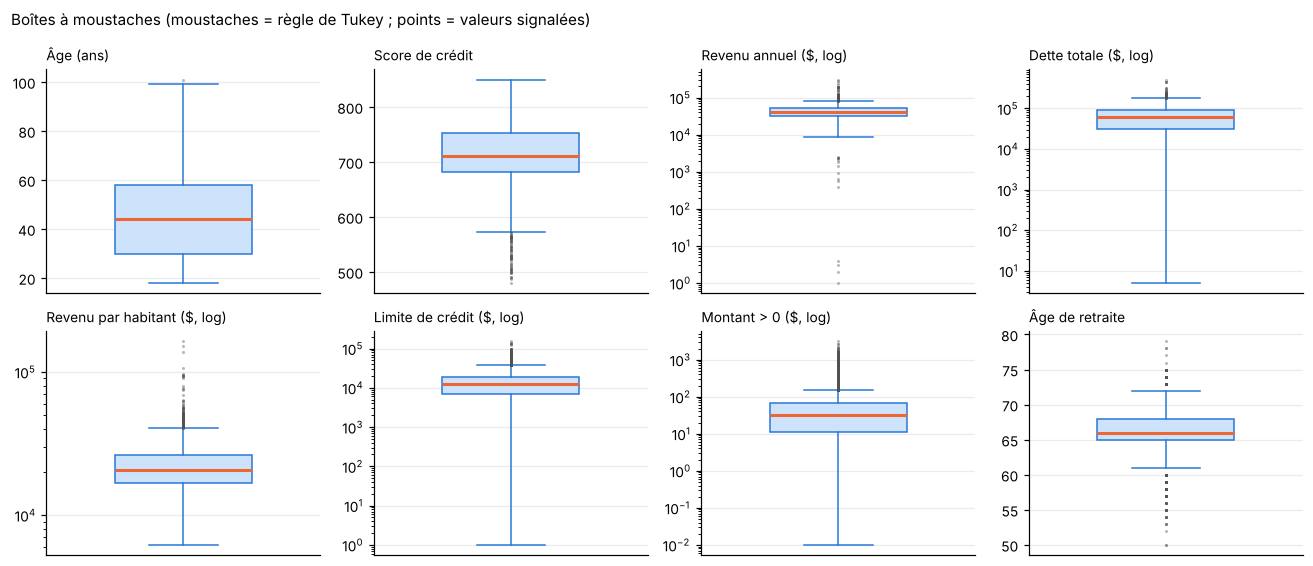

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2))
graph = [("users", "current_age", "Âge (ans)", False), ("users", "credit_score", "Score de crédit", False),
         ("users", "yearly_income", "Revenu annuel ($, log)", True), ("users", "total_debt", "Dette totale ($, log)", True),
         ("users", "per_capita_income", "Revenu par habitant ($, log)", True),
         ("cards", "credit_limit", "Limite de crédit ($, log)", True),
         ("transactions", "amount", "Montant > 0 ($, log)", True), ("users", "retirement_age", "Âge de retraite", False)]
data = {"users": users, "cards": cards, "transactions": tx}
for ax, (t, v, titre, log) in zip(axes.flat, graph):
    x = data[t][v].dropna()
    if log:
        x = x[x > 0]
    if len(x) > 200_000:
        x = x.sample(200_000, random_state=1)       # échantillon pour l'affichage seulement
    ax.boxplot(x, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=BLEU), medianprops=dict(color=ORANGE, linewidth=2),
               whiskerprops=dict(color=BLEU), capprops=dict(color=BLEU),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.4))
    if log:
        ax.set_yscale("log")
    ax.set_title(titre, fontsize=9, loc="left"); ax.set_xticks([])
fig.suptitle("Boîtes à moustaches (moustaches = règle de Tukey ; points = valeurs signalées)", fontsize=10, x=0.01, ha="left")
plt.tight_layout(); plt.show()

### Détecter n'est pas supprimer : les montants aberrants sont-ils plus souvent frauduleux ?

On compare le taux de fraude des transactions signalées par Tukey avec celui des autres, sur les transactions étiquetées seulement.

In [31]:
a = aberrations.set_index("variable").loc["amount"]
lab = tx[["transaction_id", "amount"]].merge(fraud_labels, on="transaction_id", how="inner", validate="one_to_one")
lab["classe"] = np.select([lab.amount > a.borne_haute_Tukey, lab.amount < a.borne_basse_Tukey],
                          ["au-dessus de la borne haute", "sous la borne basse"], "dans les bornes")
comp = lab.groupby("classe").agg(transactions=("fraud", "size"), fraudes=("fraud", "sum"))
comp["taux_fraude_%"] = (100 * comp.fraudes / comp.transactions).round(3)
display(comp)
print(f"Bornes de Tukey pour amount : [{a.borne_basse_Tukey:.2f} $ ; {a.borne_haute_Tukey:.2f} $]")
del lab

,transactions,fraudes,taux_fraude_%
classe,,,
au-dessus de la borne haute,445838,3424,0.768
dans les bornes,8209356,9429,0.115
sous la borne basse,259769,479,0.184


Bornes de Tukey pour amount : [-73.24 $ ; 145.88 $]


### Règles de vérification (incohérences)

Une incohérence est la violation d'une règle que les données doivent respecter (*edit rules*, semaine 07). On applique le **principe de Fellegi et Holt** : corriger ce qui est certain et signaler ce qui est douteux.

In [32]:
fin_donnees = tx["date"].max()
ouverture = tx["card_id"].map(cards.set_index("card_id")["acct_open_date"])
expiration = tx["card_id"].map(cards.set_index("card_id")["expires"]) + pd.offsets.MonthEnd(0)
age_calc = fin_donnees.year - users.birth_year - (users.birth_month > fin_donnees.month)

regles = [
    ("R1 Domaine", "18 ≤ current_age ≤ 100", "users", ~users.current_age.between(18, 100), "Signaler (âge > 100 possible mais rare)"),
    ("R2 Égalité", "current_age = âge calculé avec birth_year/birth_month (±1)", "users",
     (users.current_age - age_calc).abs() > 1, "Corriger si violée"),
    ("R3 Domaine", "300 ≤ credit_score ≤ 850", "users", ~users.credit_score.between(300, 850), "Corriger / NaN"),
    ("R4 Logique", "retirement_age < current_age ⇒ client retraité (pas une erreur)", "users",
     users.retirement_age < users.current_age, "Information : créer « retraité »"),
    ("R5 Inégalité", "expires ≥ acct_open_date", "cards", cards.expires < cards.acct_open_date, "Signaler"),
    ("R6 Inégalité", "year_pin_last_changed ≥ année d'ouverture", "cards",
     cards.year_pin_last_changed < cards.acct_open_date.dt.year, "Signaler"),
    ("R7 Domaine", "credit_limit > 0", "cards", cards.credit_limit <= 0, "NaN puis imputation (2.4)"),
    ("R8 Domaine", "acct_open_date ≤ fin des données (oct. 2019)", "cards", cards.acct_open_date > fin_donnees,
     "Signaler : date d'ouverture après la dernière transaction"),
    ("R9 Domaine", "amount > 0", "transactions", tx.amount <= 0, "Ne pas supprimer : négatif = remboursement probable"),
    ("R10 Inégalité", "date transaction ≥ mois d'ouverture du compte", "transactions", tx.date < ouverture,
     "Signaler (incohérence de date d'ouverture)"),
    ("R11 Inégalité", "date transaction ≤ fin du mois d'expiration", "transactions", tx.date > expiration,
     "Signaler : carte expirée utilisée = signal de fraude possible"),
    ("R12 Logique", "use_chip = Online ⇔ merchant_city = ONLINE", "transactions",
     (tx.use_chip == "Online Transaction") != en_ligne, "Signaler (mode de paiement incohérent)"),
]
lignes = []
for nom, forme, table, viol, piste in regles:
    n_tot = len(data[table])
    lignes.append({"regle": nom, "forme": forme, "table": table, "violations": int(viol.sum()),
                   "%": round(100 * viol.sum() / n_tot, 3), "piste_2_7": piste})
    if viol.sum():
        journal("2.6", table, nom, forme, int(viol.sum()), piste)
regles_df = pd.DataFrame(lignes)
regles_df

,regle,forme,table,violations,%,piste_2_7
0,R1 Domaine,18 ≤ current_age ≤ 100,users,1,0.050,Signaler (âge > 100 possible mais rare)
1,R2 Égalité,current_age = âge calculé avec birth_year/birth_month (±1),users,0,0.000,Corriger si violée
2,R3 Domaine,300 ≤ credit_score ≤ 850,users,0,0.000,Corriger / NaN
3,R4 Logique,retirement_age < current_age ⇒ client retraité (pas une erreur),users,277,13.850,Information : créer « retraité »
4,R5 Inégalité,expires ≥ acct_open_date,cards,0,0.000,Signaler
5,R6 Inégalité,year_pin_last_changed ≥ année d'ouverture,cards,0,0.000,Signaler
6,R7 Domaine,credit_limit > 0,cards,31,0.504,NaN puis imputation (2.4)
7,R8 Domaine,acct_open_date ≤ fin des données (oct. 2019),cards,1189,19.346,Signaler : date d'ouverture après la dernière transaction
8,R9 Domaine,amount > 0,transactions,670688,5.041,Ne pas supprimer : négatif = remboursement probable
9,R10 Inégalité,date transaction ≥ mois d'ouverture du compte,transactions,309,0.002,Signaler (incohérence de date d'ouverture)


In [33]:
# Détails utiles
print("Montants négatifs :", f"{nb(int((tx.amount < 0).sum()))}",
      "| montants nuls :", f"{nb(int((tx.amount == 0).sum()))}")
print("Montants négatifs par catégorie MCC (5 premières) :")
display(tx.loc[tx.amount < 0, "mcc"].map(mcc_codes.set_index("mcc")["categorie"]).value_counts().head(5).rename("transactions"))
print("Âge maximal :", users.current_age.max(), "| clients de plus de 100 ans :", int((users.current_age > 100).sum()))
inc = tx[(tx.use_chip == "Chip Transaction") & en_ligne]
print(f"Transactions « Chip » chez un commerçant ONLINE : {nb(len(inc))}")

Montants négatifs : 660 049 | montants nuls : 10 639
Montants négatifs par catégorie MCC (5 premières) :


mcc
Miscellaneous Food Stores            290543
Service Stations                     289072
Travel Agencies                        9016
Lodging - Hotels, Motels, Resorts      5263
Gardening Supplies                     4991
Name: transactions, dtype: int64

Âge maximal : 101 | clients de plus de 100 ans : 1
Transactions « Chip » chez un commerçant ONLINE : 5 788


In [34]:
# Valeurs aberrantes ajoutées au journal
for _, r in aberrations.iterrows():
    if r["n_Tukey"]:
        journal("2.6", r.table, r.variable,
                f"Aberrantes : Tukey {r['n_Tukey']}, z {r['n_z>3']}, z modifié {r['n_zmod>3.5']} (asymétrie {r.asymetrie:.1f})",
                int(r["n_Tukey"]), "Garder (valeurs réelles) ; winsoriser à 1 %/99 % ou passer en log pour les analyses sensibles")

**À retenir (2.6)**
- **Variables monétaires** (revenus, dette, limite de crédit, montant) :
  - elles sont très asymétriques, donc le score z est peu fiable ;
  - Tukey et le z modifié signalent davantage de valeurs ;
  - ce sont des valeurs **réelles** (gros revenus, gros achats), pas des erreurs ;
  - piste pour 2.7 : passage en log ou winsorisation, sans suppression.
- **Montants** : au-dessus de la borne haute de Tukey (≈ 146 $), le taux de fraude est de **0,77 %**, contre **0,12 %** dans les bornes, soit environ 6,7 fois plus. L'aberrant est bien un signal à garder.
- **Incohérences à signaler en 2.7** :
  - 660 049 montants **négatifs** (remboursements probables) ;
  - des transactions **avant l'ouverture** du compte ou **après l'expiration** de la carte ;
  - des cartes « ouvertes » après la fin des données ;
  - des paiements par puce chez un commerçant `ONLINE`.
- Aucune violation pour l'âge calculé, le domaine du score de crédit et les dates d'expiration.

---
# Synthèse et journal

Le journal regroupe tous les constats avec une **piste** pour la tâche 2.7. Les pistes sont des propositions : elles sont à valider en équipe avant le nettoyage.

In [35]:
journal_df = pd.DataFrame(JOURNAL)
display(journal_df)

synthese = pd.DataFrame([
    {"tache": "2.1", "jira": "KAN-10", "resultat": "Dictionnaire de données (5 tables, 47 variables) + prévu vs réel",
     "constat_cle": "Montants et dates en texte ; lat/long des transactions absentes ; card_on_dark_web constante"},
    {"tache": "2.2", "jira": "KAN-11", "resultat": "Schéma relationnel + test des jointures",
     "constat_cle": "Clés uniques ; client_id toujours cohérent avec la carte ; jointures sans multiplication"},
    {"tache": "2.3", "jira": "KAN-12", "resultat": "Rapport des types + fichiers parquet",
     "constat_cle": "Validité 100 % ; codes postaux à 5 chiffres rétablis ; mémoire divisée par 2+"},
    {"tache": "2.4", "jira": "KAN-13", "resultat": "Tableau des manquants + manquants déguisés",
     "constat_cle": "0 vrai manquant ; vides = non applicable ; 33 % sans étiquette (MCAR plausible)"},
    {"tache": "2.5", "jira": "KAN-14", "resultat": "Rapport d'intégrité",
     "constat_cle": "0 orphelin ; 33 doublons exacts et 67 nouvelles tentatives après erreur dans transactions"},
    {"tache": "2.6", "jira": "KAN-15", "resultat": "Rapport des aberrations + 12 règles de vérification",
     "constat_cle": "Variables $ très asymétriques ; gros montants plus souvent frauduleux ; incohérences de dates"},
])
synthese

,tache,table,variable,constat,n,piste_pour_2_7
0,2.1,users/cards/transactions,id,Identifiant renommé de façon explicite,3,"Garder client_id, card_id, transaction_id"
1,2.1,cards,card_on_dark_web,"Variable constante (valeur unique : No), H = 0",6146,Supprimer (aucune information) – à valider
2,2.1,users,address,"Renseignement personnel ou sensible, inutile pour l'analyse",2000,"Supprimer (principe de minimisation, Loi 25)"
3,2.1,cards,card_number,"Renseignement personnel ou sensible, inutile pour l'analyse",6146,"Supprimer (principe de minimisation, Loi 25)"
4,2.1,cards,cvv,"Renseignement personnel ou sensible, inutile pour l'analyse",6146,"Supprimer (principe de minimisation, Loi 25)"
5,2.1,transactions,latitude/longitude,Variables prévues mais absentes du fichier,0,Localiser avec merchant_state / zip à la place
6,2.2,transactions,client_id,Toujours égal au titulaire de card_id : colonne redondante mais cohérente,0,Garder pour faciliter les jointures
7,2.2,users,num_credit_cards,Égal au nombre de cartes de la table cards (redondance exacte),0,Garder (contrôle de cohérence)
8,2.4,transactions,merchant_state,Vide = transaction en ligne (non applicable),1563700,Ne pas imputer ; recoder en « ONLINE »
9,2.4,transactions,zip,"Vide = en ligne ou à l'étranger (non applicable), 0 vrai manquant",1652706,Ne pas imputer ; garder vide ou « NA_ETRANGER »


,tache,jira,resultat,constat_cle
0,2.1,KAN-10,"Dictionnaire de données (5 tables, 47 variables) + prévu vs réel",Montants et dates en texte ; lat/long des transactions absentes ; card_on_da...
1,2.2,KAN-11,Schéma relationnel + test des jointures,Clés uniques ; client_id toujours cohérent avec la carte ; jointures sans mu...
2,2.3,KAN-12,Rapport des types + fichiers parquet,Validité 100 % ; codes postaux à 5 chiffres rétablis ; mémoire divisée par 2+
3,2.4,KAN-13,Tableau des manquants + manquants déguisés,0 vrai manquant ; vides = non applicable ; 33 % sans étiquette (MCAR plausible)
4,2.5,KAN-14,Rapport d'intégrité,0 orphelin ; 33 doublons exacts et 67 nouvelles tentatives après erreur dans...
5,2.6,KAN-15,Rapport des aberrations + 12 règles de vérification,Variables $ très asymétriques ; gros montants plus souvent frauduleux ; inco...


In [36]:
# Export de tous les tableaux dans un classeur Excel (pour le rapport de la tâche 2.11)
fichier = OUT_DIR / "phase2_diagnostic_2.1_a_2.6.xlsx"
with pd.ExcelWriter(fichier) as xl:
    synthese.to_excel(xl, sheet_name="synthese", index=False)
    dictionnaire.to_excel(xl, sheet_name="2.1_dictionnaire", index=False)
    prevu_vs_reel.to_excel(xl, sheet_name="2.1_prevu_vs_reel", index=False)
    verif_cles.to_excel(xl, sheet_name="2.2_cles", index=False)
    cardinalites.to_excel(xl, sheet_name="2.2_cardinalites", index=False)
    rapport_types.to_excel(xl, sheet_name="2.3_types", index=False)
    manquants.to_excel(xl, sheet_name="2.4_manquants", index=False)
    deguises.to_excel(xl, sheet_name="2.4_manquants_deguises", index=False)
    doublons.to_excel(xl, sheet_name="2.5_doublons", index=False)
    orphelins.to_excel(xl, sheet_name="2.5_orphelins", index=False)
    inverse.to_excel(xl, sheet_name="2.5_sans_correspondance", index=False)
    pd.concat([aberrations, par_type]).round(2).to_excel(xl, sheet_name="2.6_aberrations", index=False)
    regles_df.to_excel(xl, sheet_name="2.6_regles", index=False)
    journal_df.to_excel(xl, sheet_name="journal", index=False)
print("Classeur enregistré :", fichier)

Classeur enregistré : sorties/phase2_diagnostic_2.1_a_2.6.xlsx
